# 02 · Fraud detection model — beating the static rules

**Goal:** score every payment in real time and send risky ones to a step-up check (cooling-off
period, re-authentication, or a warning screen for collect requests) instead of the current
static rules, which block legit users and miss most fraud.

**Method**
- 25 features, all computed from information available *before* the payment (verified: deleting all future
  rows leaves every feature value unchanged)
- **Time-based split:** train Jan–Apr, test May–Jun. The test set is used **once**, at the end
- **Model selection** by rolling time-series cross-validation (Feb, Mar, Apr folds) inside the training period
- **Operating threshold** chosen on an April validation month by net rupees saved, then frozen
- Fraud is ~0.23% of payments → evaluate with **PR-AUC**, not accuracy

In [1]:
import sys, warnings; sys.path.insert(0, '../src'); warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import plot_style as ps
from features import load, fraud_features, FRAUD_FEATURES
from models import make_logit, make_gbm, FraudBlend
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve
from sklearn.inspection import permutation_importance
ps.apply()
df = fraud_features(load())
X = FRAUD_FEATURES
train, test = df[df.ts < '2026-05-01'], df[df.ts >= '2026-05-01']
ytr, yte = train.is_fraud, test.is_fraud
print(f'train {len(train):,} rows, {ytr.sum()} fraud ({ytr.mean():.2%}) | test {len(test):,} rows, {yte.sum()} fraud ({yte.mean():.2%})')

train 163,234 rows, 237 fraud (0.15%) | test 152,588 rows, 504 fraud (0.33%)


## Feature intuition: fraud vs legit

In [2]:
cols = ['amt_vs_payer_mean', 'payee_prior_unique_payers', 'payee_age_days', 'is_new_device', 'is_night',
        'round_amount', 'payer_txns_1h', 'type_COLLECT', 'payer_age_band']
df.groupby('is_fraud')[cols].median().T.rename(columns={0: 'legit (median)', 1: 'fraud (median)'}).join(
    df.groupby('is_fraud')[cols].mean().T.rename(columns={0: 'legit (mean)', 1: 'fraud (mean)'}))

is_fraud,legit (median),fraud (median),legit (mean),fraud (mean)
amt_vs_payer_mean,0.548435,5.275189,1.392735,10.491060
payee_prior_unique_payers,27.000000,6.000000,339.131131,7.097166
payee_age_days,583.467350,74.773113,603.406688,81.887946
is_new_device,0.000000,0.000000,0.029294,0.307692
is_night,0.000000,0.000000,0.049708,0.222672
round_amount,0.000000,0.000000,0.019132,0.291498
payer_txns_1h,0.000000,0.000000,0.062355,0.454791
type_COLLECT,0.000000,0.000000,0.048416,0.465587
payer_age_band,1.000000,2.000000,1.436377,2.026991


## Model selection: rolling time-series cross-validation (test set untouched)
Each fold trains on all months before the validation month. With only a few hundred frauds, a single
validation month is noisy, so we compare models across three folds.

In [3]:
cands = {'Logistic regression': make_logit, 'Gradient boosting (shallow)': make_gbm, 'Blend (LR + GB)': FraudBlend}
cv = {}
for start, end, name in [('2026-02-01', '2026-03-01', 'Feb'), ('2026-03-01', '2026-04-01', 'Mar'), ('2026-04-01', '2026-05-01', 'Apr')]:
    fit, val = df[df.ts < start], df[(df.ts >= start) & (df.ts < end)]
    for k, make in cands.items():
        p = make().fit(fit[X], fit.is_fraud).predict_proba(val[X])[:, 1]
        cv.setdefault(k, {})[f'{name} ({val.is_fraud.sum()} frauds)'] = average_precision_score(val.is_fraud, p)
cv = pd.DataFrame(cv).T
cv['mean PR-AUC'] = cv.mean(axis=1)
cv.sort_values('mean PR-AUC', ascending=False).round(3)

,Feb (43 frauds),Mar (95 frauds),Apr (91 frauds),mean PR-AUC
Blend (LR + GB),0.240,0.657,0.661,0.519
Gradient boosting (shallow),0.125,0.560,0.638,0.441
Logistic regression,0.162,0.525,0.519,0.402


The blend (average of z-scored log-odds from both models, see `src/models.py`) is the best or near-best on
every fold: the linear model captures smooth risk gradients, the trees capture interactions. **We select it.**

## Final evaluation on May–Jun (the only time the test set is used)

In [4]:
lr, gb, blend = make_logit().fit(train[X], ytr), make_gbm().fit(train[X], ytr), FraudBlend().fit(train[X], ytr)
P = {'Logistic regression': lr.predict_proba(test[X])[:, 1], 'Gradient boosting': gb.predict_proba(test[X])[:, 1],
     'Blend (selected)': blend.predict_proba(test[X])[:, 1]}
rule = test.legacy_rule_flag.values
def recall_at_precision(y, p, target=0.8):
    pr, rc, _ = precision_recall_curve(y, p)
    return rc[pr >= target].max()
res = pd.DataFrame({k: {'PR-AUC': average_precision_score(yte, p), 'ROC-AUC': roc_auc_score(yte, p),
                        'Recall @ 80% precision': recall_at_precision(yte, p)} for k, p in P.items()}).T
res.loc['Legacy rules (binary)'] = [np.nan, roc_auc_score(yte, rule), np.nan]
print(f"Rules: precision {yte[rule == 1].mean():.0%}, recall {rule[yte == 1].mean():.0%}")
res.round(3)

Rules: precision 35%, recall 27%


,PR-AUC,ROC-AUC,Recall @ 80% precision
Logistic regression,0.605,0.988,0.343
Gradient boosting,0.562,0.985,0.337
Blend (selected),0.629,0.992,0.425
Legacy rules (binary),NaN,0.633,NaN


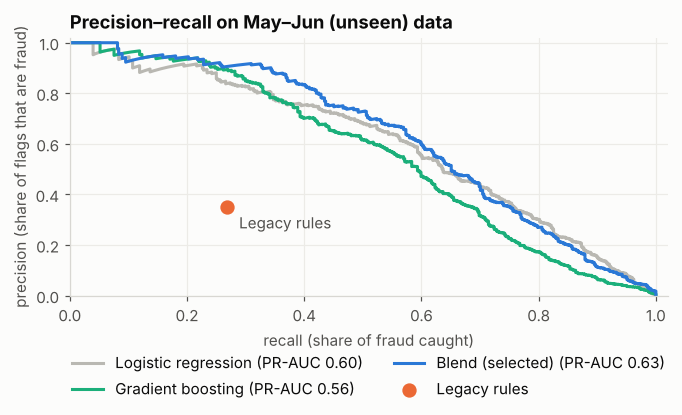

In [5]:
fig, ax = plt.subplots(figsize=(6.5, 4))
for (name, p), c in zip(P.items(), [ps.GREY, ps.AQUA, ps.BLUE]):
    pr, rc, _ = precision_recall_curve(yte, p)
    ax.plot(rc, pr, color=c, label=f'{name} (PR-AUC {average_precision_score(yte, p):.2f})')
ax.scatter([rule[yte == 1].mean()], [yte[rule == 1].mean()], s=70, color=ps.ORANGE, zorder=5, label='Legacy rules')
ax.set_xlabel('recall (share of fraud caught)'); ax.set_ylabel('precision (share of flags that are fraud)')
ax.set_title('Precision–recall on May–Jun (unseen) data'); ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.17), ncol=2); ax.set_xlim(0, 1.02); ax.set_ylim(0, 1.02)
ax.annotate('Legacy rules', (rule[yte == 1].mean(), yte[rule == 1].mean()), xytext=(8, -14), textcoords='offset points', color=ps.INK2)
fig.tight_layout(); ps.save(fig, '09_fraud_pr_curve');

## Choosing the threshold by money, on validation data
Each fraud stopped saves its amount. Each legit payment sent to step-up costs friction; we assume
**Rs 100 per false flag** (support contact + the share of users who abandon). The threshold is picked on
**April** using a model trained on Jan–Mar, then frozen and applied to the final model on May–Jun. Choosing
it on the test set would overstate the savings.

In [6]:
FP_COST = 100
def money_curve(y, s, amt, ths):
    rows = []
    for t in ths:
        f = s >= t
        tp, fp = int((f & (y == 1)).sum()), int((f & (y == 0)).sum())
        saved = amt[f & (y == 1)].sum()
        rows.append((t, tp, fp, saved, saved - fp * FP_COST))
    return pd.DataFrame(rows, columns=['threshold', 'tp', 'fp', 'fraud_saved_inr', 'net_inr'])

fit, val = df[df.ts < '2026-04-01'], df[(df.ts >= '2026-04-01') & (df.ts < '2026-05-01')]
vb = FraudBlend().fit(fit[X], fit.is_fraud)
ths = np.linspace(0.5, 0.995, 100)
vcurve = money_curve(val.is_fraud.values, vb.predict_proba(val[X])[:, 1], val.amount.values, ths)
THRESHOLD = float(vcurve.loc[vcurve.net_inr.idxmax(), 'threshold'])
print(f'Threshold chosen on April validation: {THRESHOLD:.3f}  (frozen from here on)')

y, s, amt = yte.values, P['Blend (selected)'], test.amount.values
flag = s >= THRESHOLD
k = int(rule.sum()); topk = np.argsort(-s)[:k]
def row(f):
    tp, fp = int((f & (y == 1)).sum()), int((f & (y == 0)).sum()); saved = amt[f & (y == 1)].sum()
    return [tp, fp, f'{tp / max(tp + fp, 1):.0%}', f'{tp / y.sum():.0%}', saved, saved - fp * FP_COST]
same = np.zeros(len(y), bool); same[topk] = True
summary = pd.DataFrame({'Legacy rules': row(rule == 1), f'Blend @ {THRESHOLD:.3f} (frozen)': row(flag),
                        f'Blend, same # flags as rules ({k})': row(same)},
                       index=['fraud caught', 'legit flagged', 'precision', 'recall', 'fraud value stopped (Rs)', 'net savings (Rs)'])
print(f'Total fraud value in test period: Rs {amt[y == 1].sum():,.0f}')
summary

Threshold chosen on April validation: 0.960  (frozen from here on)
Total fraud value in test period: Rs 2,853,227


,Legacy rules,Blend @ 0.960 (frozen),"Blend, same # flags as rules (385)"
fraud caught,135,335,267
legit flagged,250,367,118
precision,35%,48%,69%
recall,27%,66%,53%
fraud value stopped (Rs),1080712.0,2083946.0,1720929.0
net savings (Rs),1055712.0,2047246.0,1709129.0


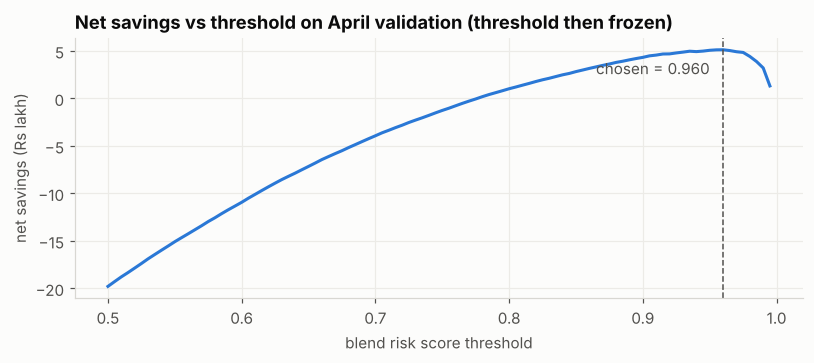

In [7]:
fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.plot(vcurve.threshold, vcurve.net_inr / 1e5, color=ps.BLUE)
ax.axvline(THRESHOLD, color=ps.INK2, ls='--', lw=1)
ax.text(THRESHOLD - 0.01, vcurve.net_inr.max() / 1e5 * 0.5, f'chosen = {THRESHOLD:.3f}', color=ps.INK2, ha='right')
ax.set_xlabel('blend risk score threshold'); ax.set_ylabel('net savings (Rs lakh)')
ax.set_title('Net savings vs threshold on April validation (threshold then frozen)')
fig.tight_layout(); ps.save(fig, '10_fraud_threshold');

## What drives the score? (permutation importance on test data)

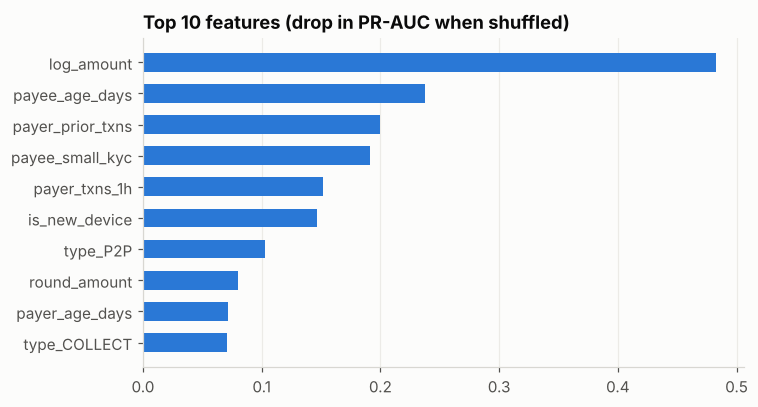

In [8]:
sample = test.sample(60000, random_state=1)
imp = permutation_importance(blend, sample[X], sample.is_fraud, scoring='average_precision',
                             n_repeats=4, random_state=1, n_jobs=-1)
fi = pd.Series(imp.importances_mean, index=X).sort_values().tail(10)
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.barh(fi.index, fi.values, color=ps.BLUE, height=0.6); ax.grid(axis='y', visible=False)
ax.set_title('Top 10 features (drop in PR-AUC when shuffled)')
fig.tight_layout(); ps.save(fig, '11_fraud_importance');

In [9]:
# Recall by fraud scheme (ground-truth scheme labels are used ONLY here, for diagnosis)
schemes = pd.read_csv('../data/ground_truth/fraud_schemes.csv')
tt = test.assign(flag=flag, rule=rule).merge(schemes, on='txn_id')
tt.groupby('fraud_scheme').agg(frauds=('txn_id', 'size'), model_recall=('flag', 'mean'), rules_recall=('rule', 'mean')).round(2)

,frauds,model_recall,rules_recall
fraud_scheme,,,
ACCOUNT_TAKEOVER,181,0.76,0.75
COLLECT_SCAM,233,0.71,0.00
FAKE_QR,90,0.34,0.00


## Takeaways
- The blended model beats the static rules on every axis: **for the same number of flags it catches about
  twice as much fraud**, and at the validation-chosen threshold it stops far more fraud value net of friction cost.
- Beyond the amount itself, the strongest signals are about the **payee** (how new the account is, its KYC tier) and
  the **payer's behaviour** (how established the account is, bursts of payments in the last hour, a new device). A static rule set
  can't express these well.
- Collect-request scams, which the rules miss entirely, are caught most of the time. Fake-merchant QR fraud is the
  weak spot: merchant-side features (refund rate, complaint history) are the next thing to add.
- **Deployment idea:** score → (a) high risk: hold + re-authenticate; (b) medium + COLLECT: full-screen
  "you are about to SEND money" warning; (c) confirmed mule accounts feed a blocklist.
- Limitations: synthetic labels arrive instantly; in production fraud labels lag by weeks, so the training
  window must exclude the most recent days and the model needs drift monitoring.